## 50. Program -4 - Animating the Kinematic Mechanism - Pendulum Animation

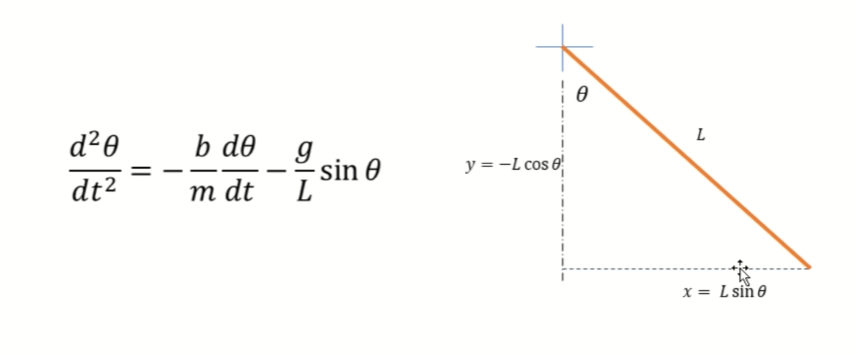

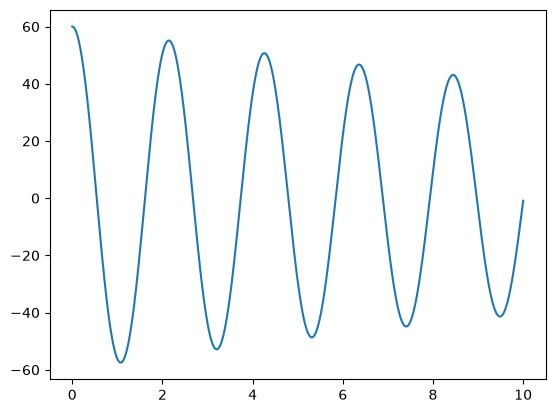

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib.animation as anm

def pendulum_motion(X,t):

    m = 2 # mass
    g = 9.81
    b= 0.15 # damping
    l = 1 # length of the pendulum

    theta = X[0]
    dtheta = X[1]
    d2theta = -(b/m)*dtheta - (g/l)*np.sin(theta)

    return [dtheta, d2theta]

X0 = [np.pi/3,0]  #60deg
time_step = 0.01
time = np.arange(0,10+time_step,time_step)
soln = odeint(pendulum_motion,X0,time)


theta = soln[:,0]

plt.plot(time,theta*180/np.pi)
plt. show()

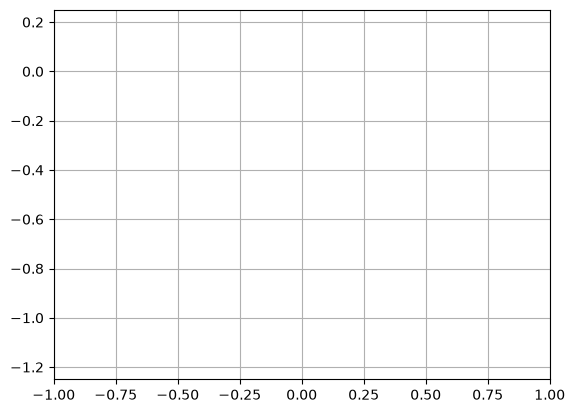

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib.animation as anm

def pendulum_motion(X,t):

    m = 2 # mass
    g = 9.81
    b= 0.15 # damping
    l = 1 # length of the pendulum

    theta = X[0]
    dtheta = X[1]
    d2theta = -(b/m)*dtheta - (g/l)*np.sin(theta)

    return [dtheta, d2theta]

X0 = [np.pi/3,0]  #60deg
time_step = 0.01
time = np.arange(0,10+time_step,time_step)
soln = odeint(pendulum_motion,X0,time)


theta = soln[:,0]

L= 1
x = L+np.sin(theta)
y = -L*np.cos(theta)

pend_fig = plt.figure()
ax = pend_fig.add_subplot()
ax.set_xlim(-L,L)
ax.set_ylim(-1.25*L,0.25)
ax.grid()

line = ax.plot([],[])
def pend_anim(i):
    xp = (0,x[i])
    yp = (0,y[i])
    line.set_xdata(xp)
    line.set_ydata(yp)

    return line


anim = anm.FuncAnimation(pend_fig,pend_anim,frames=len(soln),interval=0.01)


#plt.plot(time,theta*180/np.pi)
plt. show()

#should  runbut  not working 

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib.animation as anm

def pendulum_motion(X,t):

    m = 2 # mass
    g = 9.81
    b= 0.15 # damping
    l = 1 # length of the pendulum

    theta = X[0]
    dtheta = X[1]
    d2theta = -(b/m)*dtheta - (g/l)*np.sin(theta)

    return [dtheta, d2theta]

X0 = [np.pi/3,0]  #60deg
time_step = 0.01
time = np.arange(0,10+time_step,time_step)
soln = odeint(pendulum_motion,X0,time)


theta = soln[:,0]

L= 1
x = L*np.sin(theta)
y = -L*np.cos(theta)

pend_fig = plt.figure()
ax = pend_fig.add_subplot()
ax.set_xlim(-L,L)
ax.set_ylim(-1.25*L,0.25)
ax.grid()

time_templet ='Time =%0.3fs'
time_text=ax.text(0.5,0,'')


line = ax.plot([],[])
def pend_anim(i):
    xp = (0,x[i])
    yp = (0,y[i])
    line.set_xdata(xp)
    line.set_ydata(yp)

    return (line,)


anim = anm.FuncAnimation(pend_fig,pend_anim,frames=len(soln),interval=0.01)


#plt.plot(time,theta*180/np.pi)
plt. show()

#should  runbut  not working 

Traceback (most recent call last):
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\cbook.py", line 390, in process
    func(*args, **kwargs)
    ~~~~^^^^^^^^^^^^^^^^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 939, in _start
    self._init_draw()
    ~~~~~~~~~~~~~~~^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 1789, in _init_draw
    self._draw_frame(frame_data)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 1807, in _draw_frame
    self._drawn_artists = self._func(framedata, *self._args)
                          ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\skatikit\AppData\Local\Temp\ipykernel_4760\2608060920.py", line 45, in pend_anim
    line.set_xdata(xp)
    ^^^^^^^^^^^^^^
AttributeError: 'list' object has no attribute 'set_xdata

In [8]:
# AI  fix 
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib.animation as anm

def pendulum_motion(X, t):
    m = 2  # mass
    g = 9.81
    b = 0.15  # damping
    l = 1  # length of the pendulum

    theta = X[0]
    dtheta = X[1]
    d2theta = -(b/m)*dtheta - (g/l)*np.sin(theta)

    return [dtheta, d2theta]

X0 = [np.pi/3, 0]  # 60deg
time_step = 0.01
time = np.arange(0, 10 + time_step, time_step)
soln = odeint(pendulum_motion, X0, time)

theta = soln[:,0]

L = 1
# FIX 1: Changed '+' to '*' so coordinates calculate properly
x = L * np.sin(theta)
y = -L * np.cos(theta)

pend_fig = plt.figure()
ax = pend_fig.add_subplot()
ax.set_xlim(-L, L)
ax.set_ylim(-1.25*L, 0.25)
ax.grid()

# FIX 2: Added a marker 'o-' to visually display the pendulum bob
# Added a comma after 'line' because ax.plot returns a list of Line2D objects
line, = ax.plot([], [], 'o-', lw=2)

time_template = 'Time = %0.5fs'
time_text = ax.text(0.5,0,'')


def pend_anim(i):
    xp = (0, x[i])
    yp = (0, y[i])
    line.set_data(xp, yp)  # Cleaner way to update both x and y
    
    time_text.set_text(time_template %(i*time_step))

    # FIX 3: Returned as a tuple/list containing the line object
    return (line,)

# Adjusted interval to 10ms to match your 0.01s time step for real-time speed
anim = anm.FuncAnimation(pend_fig, pend_anim, frames=len(soln), interval=10, blit=True)

plt.show()


Exception in Tkinter callback
Traceback (most recent call last):
  File "c:\Program Files\Python314\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "c:\Program Files\Python314\Lib\tkinter\__init__.py", line 876, in callit
    func(*args, **kw)
    ~~~~^^^^^^^^^^^^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\backends\_backend_tk.py", line 170, in _on_timer
    super()._on_timer()
    ~~~~~~~~~~~~~~~~~^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\backend_bases.py", line 1165, in _on_timer
    ret = func(*args, **kwargs)
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 1470, in _step
    still_going = super()._step(*args)
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 1158, in _step
    self._draw_next_frame(framedata, self._blit)
    

In [2]:
# Working AI FIX
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib.animation as anm

# --- FIX FOR TKINTER BACKEND ---
# Explicitly tell matplotlib to use the Tkinter (TkAgg) backend for rendering the window
import matplotlib
matplotlib.use('TkAgg')

def pendulum_motion(X, t):
    m = 2  # mass
    g = 9.81
    b = 0.15  # damping
    l = 1  # length of the pendulum

    theta = X[0]
    dtheta = X[1]
    d2theta = -(b/m)*dtheta - (g/l)*np.sin(theta)

    return [dtheta, d2theta]

X0 = [np.pi/3, 0]  # 60deg
time_step = 0.01
time = np.arange(0, 10 + time_step, time_step)
soln = odeint(pendulum_motion, X0, time)

theta = soln[:,0]

L = 1
# FIX 1: Changed '+' to '*' so coordinates calculate properly
x = L * np.sin(theta)
y = -L * np.cos(theta)

pend_fig = plt.figure()
ax = pend_fig.add_subplot()
ax.set_xlim(-L, L)
ax.set_ylim(-1.25*L, 0.25)
ax.grid()

# FIX 2: Added a marker 'o-' to visually display the pendulum bob
# Added a comma after 'line' because ax.plot returns a list of Line2D objects
line, = ax.plot([], [], 'o-', lw=2)

def pend_anim(i):
    xp = (0, x[i])
    yp = (0, y[i])
    line.set_data(xp, yp)  # Cleaner way to update both x and y

    # FIX 3: Returned as a tuple/list containing the line object
    return (line,)

# Adjusted interval to 10ms to match your 0.01s time step for real-time speed
anim = anm.FuncAnimation(pend_fig, pend_anim, frames=len(soln), interval=10, blit=True)

plt.show()


Exception in Tkinter callback
Traceback (most recent call last):
  File "c:\Program Files\Python314\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "c:\Program Files\Python314\Lib\tkinter\__init__.py", line 876, in callit
    func(*args, **kw)
    ~~~~^^^^^^^^^^^^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\backends\_backend_tk.py", line 170, in _on_timer
    super()._on_timer()
    ~~~~~~~~~~~~~~~~~^^
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\backend_bases.py", line 1165, in _on_timer
    ret = func(*args, **kwargs)
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 1470, in _step
    still_going = super()._step(*args)
  File "C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py", line 1158, in _step
    self._draw_next_frame(framedata, self._blit)
    

In [ ]:
#workes  in JUPITER 

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib.animation as anm
from IPython.display import HTML  # New import for Jupyter rendering

def pendulum_motion(X, t):
    m = 2  # mass
    g = 9.81
    b = 0.15  # damping
    l = 1  # length of the pendulum

    theta = X[0]
    dtheta = X[1]
    d2theta = -(b/m)*dtheta - (g/l)*np.sin(theta)

    return [dtheta, d2theta]

# Physics Setup
X0 = [np.pi/3, 0]  # 60deg
time_step = 0.01
time = np.arange(0, 10 + time_step, time_step)
soln = odeint(pendulum_motion, X0, time)

theta = soln[:, 0]
L = 1
x = L * np.sin(theta)
y = -L * np.cos(theta)

# Plot Setup
pend_fig = plt.figure()
ax = pend_fig.add_subplot()
ax.set_xlim(-L, L)
ax.set_ylim(-1.25 * L, 0.25)
ax.grid()

# Unpack the line artist using a comma
line, = ax.plot([], [], 'o-', lw=2)

def pend_anim(i):
    xp = (0, x[i])
    yp = (0, y[i])
    line.set_data(xp, yp)
    return (line,)

# Build the animation object
anim = anm.FuncAnimation(pend_fig, pend_anim, frames=len(soln), interval=10, blit=True)

# Close the static plot window so it doesn't duplicate blank figures below
plt.close(pend_fig)

# Display the video player interface inline inside Jupyter
HTML(anim.to_jshtml())


C:\Users\skatikit\AppData\Roaming\Python\Python314\site-packages\matplotlib\animation.py:920: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import matplotlib. animation as anm

def pendulum_mot(X,t):
    m = 1
    g = 9.81
    b = 0.1
    l=1
    theta = X[0]
    dtheata = X[1]
    d2theta = -(b/m)*dtheata -(g/1)*np.sin(theta)
    return [dtheata, d2theta]

X0 = [np.pi/4,0]
time_step = 0.1
time = np.arange(0,10+time_step,time_step)
soln = odeint(pendulum_mot,X0,time)

disp = soln[:,0]
vel = soln[:,1]
l =1
x = l*np.sin(disp)
y= -l*np.cos(disp)
